<a href="https://colab.research.google.com/github/chipojaya1/ISS-Economic-Distance/blob/main/Economic_distance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Prepare environment and load the data

In [1]:
# define necessary libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches

from scipy.spatial import distance
import seaborn as sns
sns.set_theme(style="darkgrid")

In [2]:
# load wdi data as wdi from my github
df = pd.read_excel('https://github.com/chipojaya1/ISS-Economic-Distance/blob/main/data/WDI_Raw_2019.xlsx?raw=true')

print("df type:", type(df))
print("df shape:", df.shape)
df.head()

df type: <class 'pandas.core.frame.DataFrame'>
df shape: (873, 5)


,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..
4,Albania,ALB,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,5072.436484


In [3]:
# 1. Clean up potential leading/trailing whitespaces in string columns
df['Series Name'] = df['Series Name'].str.strip()
display(df.head())

,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,"Inflation, GDP deflator (annual %)",NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,Imports of goods and services (% of GDP),NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,Exports of goods and services (% of GDP),NE.EXP.GNFS.ZS,..
4,Albania,ALB,GDP per capita (constant 2015 US$),NY.GDP.PCAP.KD,5072.436484


In [4]:
# 2. Define the mapping for Series Name renaming
name_mapping = {
    'GDP per capita (constant 2015 US$)': 'gdp_per_capita',
    'Inflation, GDP deflator (annual %)': 'inflation',
    'Imports of goods and services (% of GDP)': 'imports',
    'Exports of goods and services (% of GDP)': 'exports'
}

# Filter to keep only the series we are interested in and map their names
df_filtered = df[df['Series Name'].isin(name_mapping.keys())].copy()
df_filtered['Series Name'] = df_filtered['Series Name'].map(name_mapping)
display(df_filtered.head())

,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,gdp_per_capita,NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,inflation,NY.GDP.DEFL.KD.ZG,6.52148
2,Afghanistan,AFG,imports,NE.IMP.GNFS.ZS,..
3,Afghanistan,AFG,exports,NE.EXP.GNFS.ZS,..
4,Albania,ALB,gdp_per_capita,NY.GDP.PCAP.KD,5072.436484


In [5]:
# 3. Clean the value column: replace '..' with NaN and convert to float
val_col = '2019 [YR2019]'
df_filtered[val_col] = df_filtered[val_col].replace('..', np.nan)
df_filtered[val_col] = pd.to_numeric(df_filtered[val_col], errors='coerce')
display(df_filtered.head())

/tmp/ipykernel_900/3241800311.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_filtered[val_col] = df_filtered[val_col].replace('..', np.nan)


,Country Name,Country Code,Series Name,Series Code,2019 [YR2019]
0,Afghanistan,AFG,gdp_per_capita,NY.GDP.PCAP.KD,557.861533
1,Afghanistan,AFG,inflation,NY.GDP.DEFL.KD.ZG,6.521480
2,Afghanistan,AFG,imports,NE.IMP.GNFS.ZS,NaN
3,Afghanistan,AFG,exports,NE.EXP.GNFS.ZS,NaN
4,Albania,ALB,gdp_per_capita,NY.GDP.PCAP.KD,5072.436484


In [6]:
# 4. Pivot from long to wide (short) format
df_wide = df_filtered.pivot(index=['Country Name', 'Country Code'], columns='Series Name', values=val_col).reset_index()

# Reset column index name
df_wide.columns.name = None

# Display the cleaned and reshaped DataFrame
print("df_wide shape:", df_wide.shape)
display(df_wide.head())

df_wide shape: (217, 6)


,Country Name,Country Code,exports,gdp_per_capita,imports,inflation
0,Afghanistan,AFG,NaN,557.861533,NaN,6.521480
1,Albania,ALB,30.936122,5072.436484,44.446006,1.000633
2,Algeria,DZA,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,ASM,61.669243,12524.016025,94.899536,1.748289
4,Andorra,AND,NaN,39346.275036,NaN,1.374754


In [7]:
# rename column Country Name to country, drop country code and mask df as wdi_df
wdi_df = df_wide.rename(columns={'Country Name': 'country'}).drop(columns=['Country Code'])
print("wdi_df shape:", wdi_df.shape)
wdi_df.head()

wdi_df shape: (217, 5)


,country,exports,gdp_per_capita,imports,inflation
0,Afghanistan,NaN,557.861533,NaN,6.521480
1,Albania,30.936122,5072.436484,44.446006,1.000633
2,Algeria,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,61.669243,12524.016025,94.899536,1.748289
4,Andorra,NaN,39346.275036,NaN,1.374754


####2. Summarize the individual sub-components of the distance measure. Report and interpret the minimum, maximum, mean, median, standard deviation for each of the sub-components and the correlation between each of these sub-components

Explore summary statistics  and correlation coefficients



In [8]:
wdi_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 217 entries, 0 to 216
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         217 non-null    object 
 1   exports         183 non-null    float64
 2   gdp_per_capita  208 non-null    float64
 3   imports         183 non-null    float64
 4   inflation       209 non-null    float64
dtypes: float64(4), object(1)
memory usage: 8.6+ KB


In [9]:
# Summary statistics
summary_stats = wdi_df.describe()
print("Summary Statistics:")
display(summary_stats)

Summary Statistics:


,exports,gdp_per_capita,imports,inflation
count,183.000000,208.000000,183.000000,209.000000
mean,43.059452,17544.183111,48.085723,110.387032
std,31.529306,24664.928816,28.529602,1515.376731
min,7.779936,270.411006,10.607517,-4.603271
25%,22.282452,2423.171056,28.704516,0.848015
50%,36.400882,6533.112217,41.469590,2.375860
75%,52.400877,21751.331731,58.928664,4.175673
max,206.580146,185582.668516,176.092206,21909.342668


In [10]:
# Missing data
missing_data = wdi_df.isnull().sum()
print("\nMissing Data:")
display(missing_data)


Missing Data:


,0
country,0
exports,34
gdp_per_capita,9
imports,34
inflation,8


In [11]:
# Drop any country with missing values in each of the 3 indicators
cols = ['gdp_per_capita', 'inflation', 'imports', 'exports']
wdi_df = wdi_df.dropna(subset=cols)
print("wdi_df shape:", wdi_df.shape)
wdi_df.head()

wdi_df shape: (182, 5)


,country,exports,gdp_per_capita,imports,inflation
1,Albania,30.936122,5072.436484,44.446006,1.000633
2,Algeria,20.407942,4672.664087,26.098901,0.882993
3,American Samoa,61.669243,12524.016025,94.899536,1.748289
5,Angola,36.950082,3105.599712,23.421225,20.249856
6,Antigua and Barbuda,69.164695,18525.258891,68.373089,0.712335


In [12]:
wdi_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 182 entries, 1 to 216
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   country         182 non-null    object 
 1   exports         182 non-null    float64
 2   gdp_per_capita  182 non-null    float64
 3   imports         182 non-null    float64
 4   inflation       182 non-null    float64
dtypes: float64(4), object(1)
memory usage: 8.5+ KB


In [13]:
# ============================================================
# EXPLORATORY DATA ANALYSIS — IMPROVED VISUALIZATIONS
# World Development Indicators, 2019
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import numpy as np
import pandas as pd

# Keep a consistent style across all figures
sns.set_theme(style="whitegrid", context="notebook")

MAIN_COLOR = "#277C69"
MEAN_COLOR = "#C65D43"
MEDIAN_COLOR = "#34495E"

cols = ["gdp_per_capita", "inflation", "imports", "exports"]

# Keep complete observations across all four indicators
plot_df = wdi_df.dropna(subset=cols).copy()

print(f"Economies included in analysis: {len(plot_df)}")

Economies included in analysis: 182


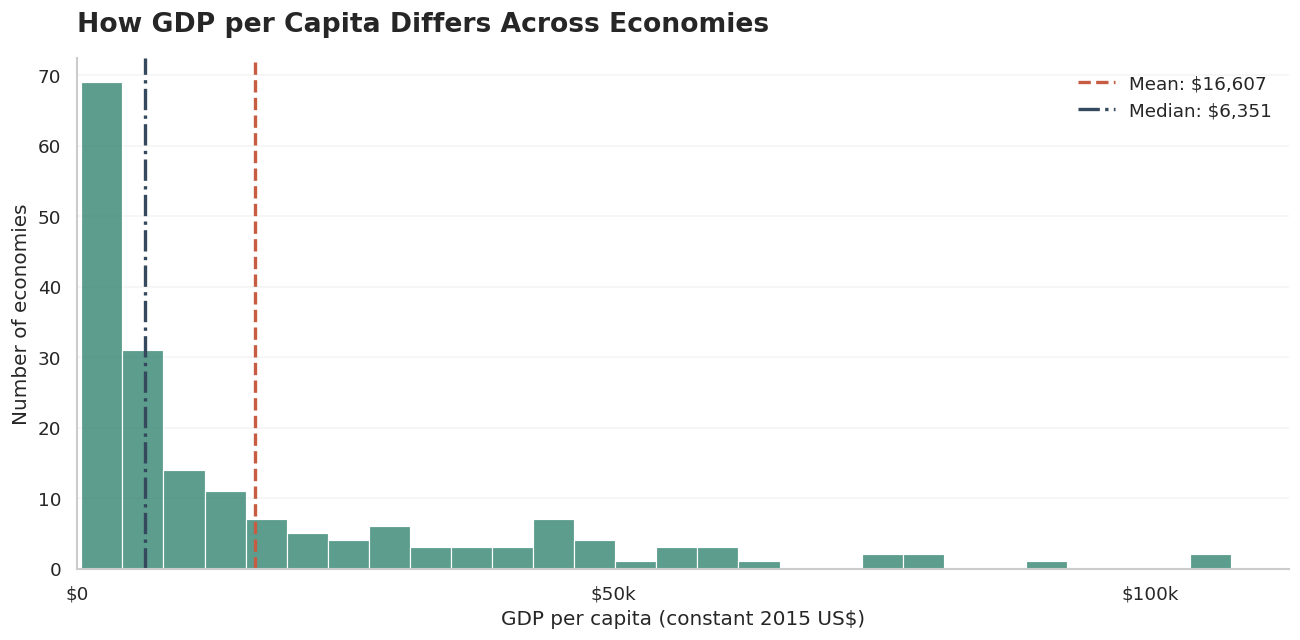

In [14]:
# ============================================================
# FIGURE 1: GDP PER CAPITA DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=120)

sns.histplot(
    data=plot_df,
    x="gdp_per_capita",
    bins=28,
    color=MAIN_COLOR,
    edgecolor="white",
    linewidth=0.7,
    ax=ax
)

gdp_mean = plot_df["gdp_per_capita"].mean()
gdp_median = plot_df["gdp_per_capita"].median()

ax.axvline(
    gdp_mean,
    color=MEAN_COLOR,
    linestyle="--",
    linewidth=2,
    label=f"Mean: ${gdp_mean:,.0f}"
)

ax.axvline(
    gdp_median,
    color=MEDIAN_COLOR,
    linestyle="-.",
    linewidth=2,
    label=f"Median: ${gdp_median:,.0f}"
)

ax.set_title(
    "How GDP per Capita Differs Across Economies",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=16
)

ax.set_xlabel("GDP per capita (constant 2015 US$)")
ax.set_ylabel("Number of economies")

# Normal dollar axis, NOT a logarithmic axis
ax.set_xlim(left=0)
ax.xaxis.set_major_locator(ticker.MultipleLocator(50000))
ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda x, pos: "$0" if x == 0 else f"${x/1000:,.0f}k"
    )
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()


GDP per capita varies greatly across economies. Most have relatively low economic output per person, while a much smaller group has considerably higher values. This difference highlights the unequal distribution of economic resources and productive capacity across the world.

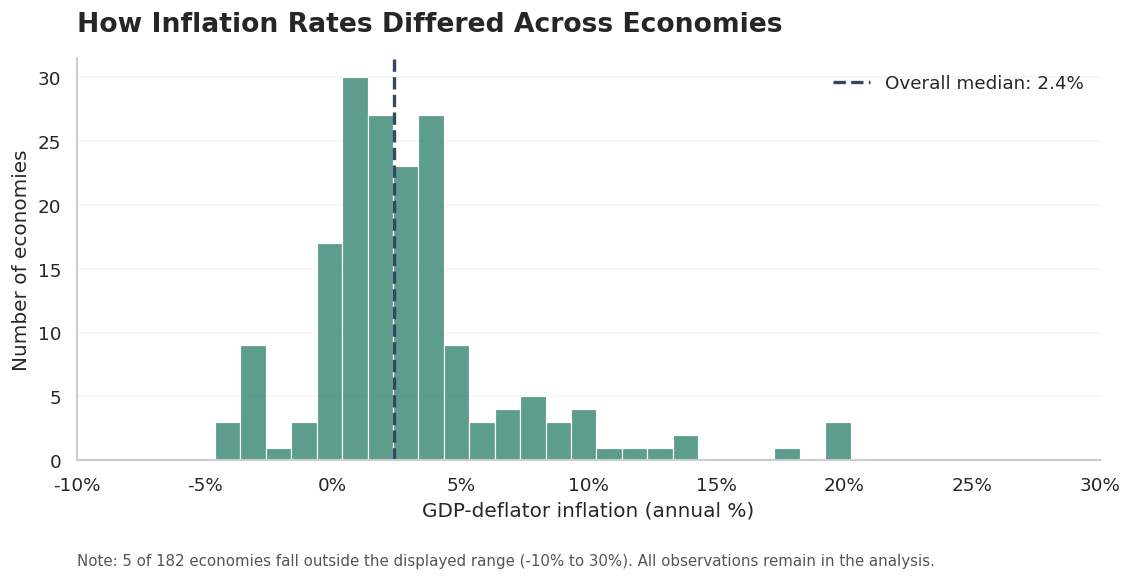

In [15]:
# ============================================================
# FIGURE 2: INFLATION DISTRIBUTION
# ============================================================

# Inflation has exceptionally large outliers.
# We focus the DISPLAY on a readable range, but retain
# all observations in the dataset and later calculations.

inflation_display_min = -10
inflation_display_max = 30

inflation_visible = plot_df[
    plot_df["inflation"].between(
        inflation_display_min,
        inflation_display_max
    )
].copy()

outside_count = len(plot_df) - len(inflation_visible)

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=120)

sns.histplot(
    data=inflation_visible,
    x="inflation",
    bins=25,
    color=MAIN_COLOR,
    edgecolor="white",
    linewidth=0.7,
    ax=ax
)

inflation_median = plot_df["inflation"].median()

ax.axvline(
    inflation_median,
    color=MEDIAN_COLOR,
    linestyle="--",
    linewidth=2,
    label=f"Overall median: {inflation_median:.1f}%"
)

ax.set_title(
    "How Inflation Rates Differed Across Economies",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=16
)

ax.set_xlabel("GDP-deflator inflation (annual %)")
ax.set_ylabel("Number of economies")

ax.set_xlim(inflation_display_min, inflation_display_max)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:.0f}%")
)

ax.text(
    0,
    -0.23,
    f"Note: {outside_count} of {len(plot_df)} economies fall "
    f"outside the displayed range (-10% to 30%). "
    "All observations remain in the analysis.",
    transform=ax.transAxes,
    fontsize=9,
    color="#555555",
    ha="left",
    va="top",
    wrap=True
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

sns.despine()
plt.subplots_adjust(bottom=0.27)
plt.show()

Most economies experienced relatively modest inflation in 2019. However, some experienced exceptionally high inflation rates. These extreme cases show that economic conditions differed substantially across economies, particularly in terms of price stability.

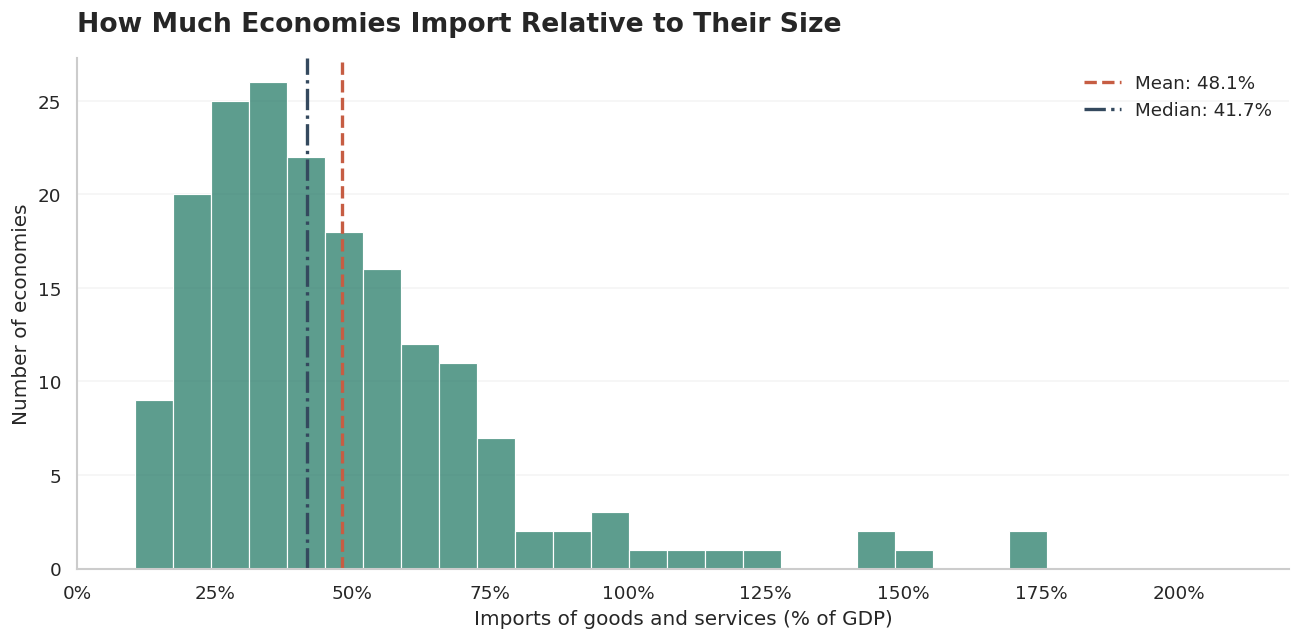

In [16]:
# ============================================================
# FIGURE 3: IMPORTS DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=120)

sns.histplot(
    data=plot_df,
    x="imports",
    bins=24,
    color=MAIN_COLOR,
    edgecolor="white",
    linewidth=0.7,
    ax=ax
)

imports_mean = plot_df["imports"].mean()
imports_median = plot_df["imports"].median()

ax.axvline(
    imports_mean,
    color=MEAN_COLOR,
    linestyle="--",
    linewidth=2,
    label=f"Mean: {imports_mean:.1f}%"
)

ax.axvline(
    imports_median,
    color=MEDIAN_COLOR,
    linestyle="-.",
    linewidth=2,
    label=f"Median: {imports_median:.1f}%"
)

ax.set_title(
    "How Much Economies Import Relative to Their Size",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=16
)

ax.set_xlabel("Imports of goods and services (% of GDP)")
ax.set_ylabel("Number of economies")

ax.set_xlim(left=0, right=220)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:.0f}%")
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

Economies differ in how much they purchase from the rest of the world relative to the size of their economies. Some rely more heavily on international goods and services, while others import a smaller share of their GDP.

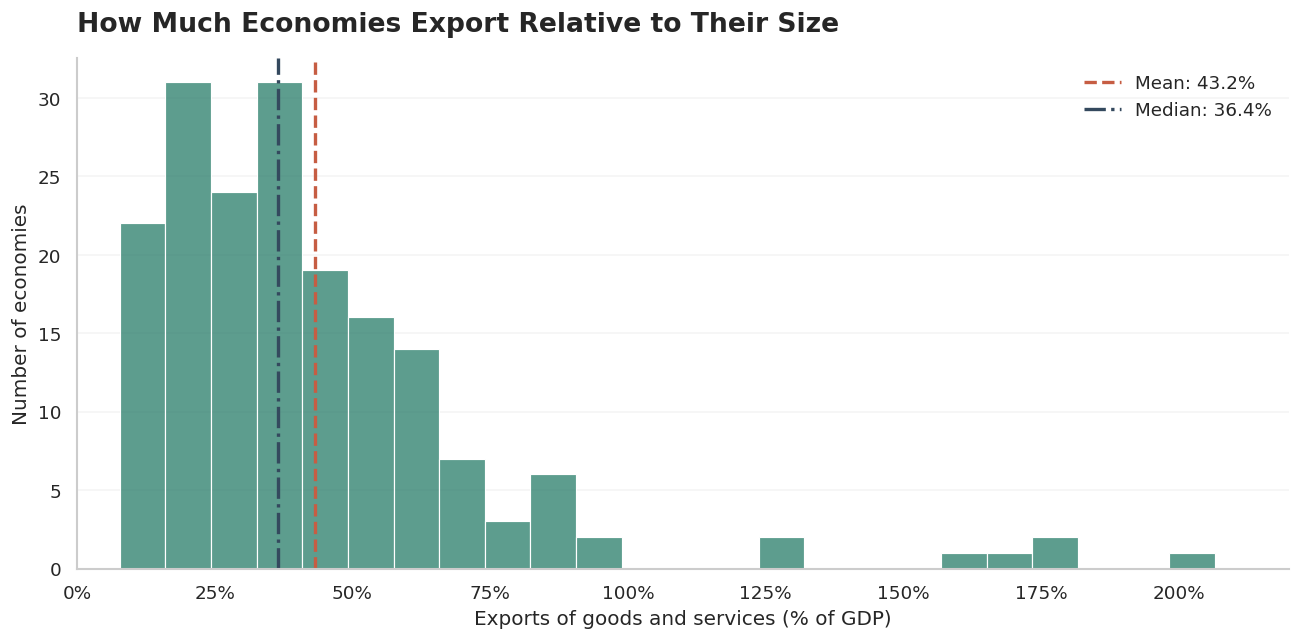

In [17]:
# ============================================================
# FIGURE 4: EXPORTS DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(11, 5.5), dpi=120)

sns.histplot(
    data=plot_df,
    x="exports",
    bins=24,
    color=MAIN_COLOR,
    edgecolor="white",
    linewidth=0.7,
    ax=ax
)

exports_mean = plot_df["exports"].mean()
exports_median = plot_df["exports"].median()

ax.axvline(
    exports_mean,
    color=MEAN_COLOR,
    linestyle="--",
    linewidth=2,
    label=f"Mean: {exports_mean:.1f}%"
)

ax.axvline(
    exports_median,
    color=MEDIAN_COLOR,
    linestyle="-.",
    linewidth=2,
    label=f"Median: {exports_median:.1f}%"
)

ax.set_title(
    "How Much Economies Export Relative to Their Size",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=16
)

ax.set_xlabel("Exports of goods and services (% of GDP)")
ax.set_ylabel("Number of economies")

# Match the imports scale for easier comparison
ax.set_xlim(left=0, right=220)

ax.xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x:.0f}%")
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.grid(axis="x", visible=False)

sns.despine()
plt.tight_layout()
plt.show()

Exports also vary considerably. Some economies sell a much larger share of their goods and services internationally than others. This illustrates differences in how strongly economies participate in international trade.

In [19]:
# ============================================================
# SPEARMAN CORRELATIONS
# ============================================================

spearman_correlations = plot_df[cols].corr(method="spearman")

print("Pearson correlations:")
display(correlations.round(3))

print("Spearman correlations:")
display(spearman_correlations.round(3))


Pearson correlations:


,gdp_per_capita,inflation,imports,exports
gdp_per_capita,1.000,-0.053,0.272,0.484
inflation,-0.053,1.000,-0.099,0.007
imports,0.272,-0.099,1.000,0.848
exports,0.484,0.007,0.848,1.000


Spearman correlations:


,gdp_per_capita,inflation,imports,exports
gdp_per_capita,1.000,-0.294,0.239,0.550
inflation,-0.294,1.000,-0.224,-0.309
imports,0.239,-0.224,1.000,0.722
exports,0.550,-0.309,0.722,1.000


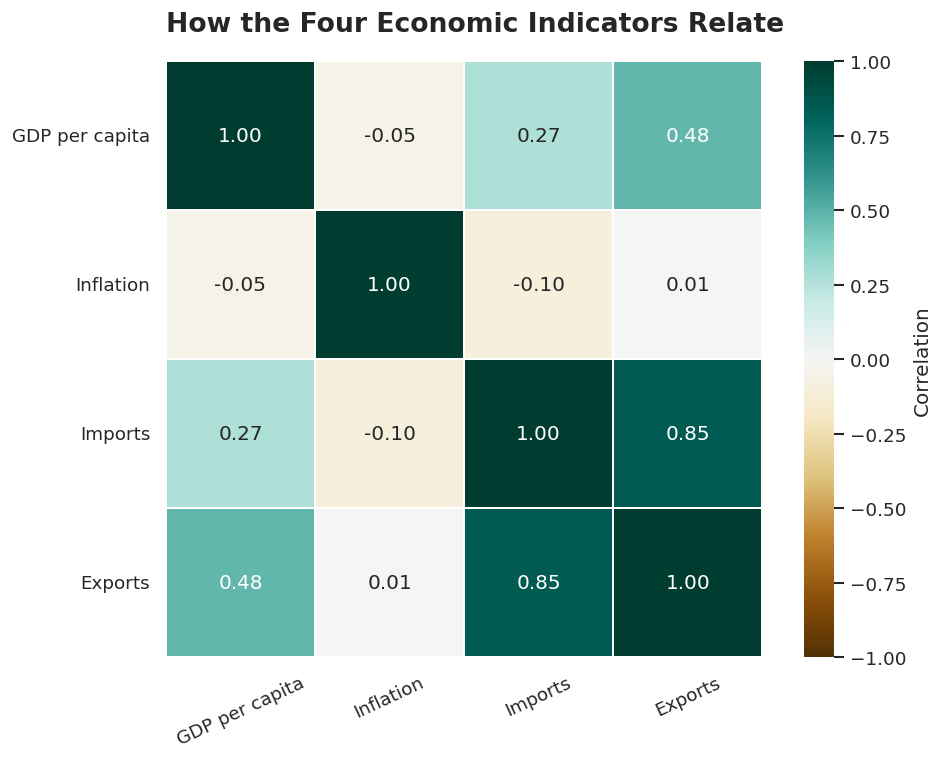

In [18]:
# ============================================================
# FIGURE 5: CORRELATION HEATMAP
# ============================================================

# Pearson correlation is consistent with your original analysis
correlations = plot_df[cols].corr(method="pearson")

labels = [
    "GDP per capita",
    "Inflation",
    "Imports",
    "Exports"
]

fig, ax = plt.subplots(figsize=(8.5, 6.5), dpi=120)

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="BrBG",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=1,
    linecolor="white",
    xticklabels=labels,
    yticklabels=labels,
    cbar_kws={"label": "Correlation"},
    ax=ax
)

ax.set_title(
    "How the Four Economic Indicators Relate",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=18
)

ax.tick_params(axis="x", rotation=25)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


### Interpreting the Correlation Heatmap

The heatmap shows how the four economic indicators relate to one another across economies in 2019.

The strongest relationship is between imports and exports (0.85). This suggests that economies that import more goods and services relative to their GDP also tend to export more. In other words, economies that are more engaged in international trade often have higher levels of both imports and exports.

GDP per capita has a moderate positive relationship with exports (0.48) and a weaker positive relationship with imports (0.27). This suggests that economies with higher economic output per person tend to have somewhat greater participation in international trade, particularly through exports.

Inflation has very weak relationships with the other three indicators. This suggests that differences in inflation do not closely follow differences in GDP per capita or trade activity across the economies studied.

A correlation of 0.85 does not necessarily mean trade causes economic growth or that importing causes exporting. It simply means those two indicators tend to move together across the economies in your dataset.

**Overall, the heatmap shows that the four indicators capture different aspects of economic conditions, although imports and exports are closely related.** This is important for the next stage of the analysis, where Mahalanobis distance is used to measure how economically different each economy is from the United States while accounting for relationships between the indicators.

####3. Calculate the distance measure using the Mahalanobis distance.
- Explain why you use the Mahalanobis distance over the Euclidean distance. Stata offers some canned programs including one to calcuate the Mahalanobis distance caled mahapick. This doesn't come with the standard installation so you need to first install it.
- The command to compute distance is below:
mahascores gdp_per_cap imports exports, idvar(country) genfile(mahadist) compute_invcov
- This creates a new file called "mahadist" which has all the distance scores.

In [20]:
# Economies at each observed extreme
indicators = ['gdp_per_capita', 'inflation', 'imports', 'exports']

extremes = []
for col in indicators:
    # Find the row with the minimum value for this indicator
    min_row = wdi_df.loc[wdi_df[col].idxmin()]
    # Find the row with the maximum value for this indicator
    max_row = wdi_df.loc[wdi_df[col].idxmax()]

    extremes.append({
        'Indicator': col,
        'Min Country': min_row['country'],
        'Min Value': min_row[col],
        'Max Country': max_row['country'],
        'Max Value': max_row[col]
    })

extremes_df = pd.DataFrame(extremes)
display(extremes_df)

,Indicator,Min Country,Min Value,Max Country,Max Value
0,gdp_per_capita,Central African Republic,401.825822,Luxembourg,107591.899505
1,inflation,Naoero,-4.603271,"Venezuela, RB",21909.342668
2,imports,Cuba,10.607517,"Hong Kong SAR, China",176.092206
3,exports,Nepal,7.779936,Luxembourg,206.580146


Mahalanobis Distance

In [21]:
# 1. Select the indicators to use for distance calculation
features = ['gdp_per_capita', 'inflation', 'imports', 'exports']

# 2. Filter out rows that have NaN values in our key features
wdi_clean = wdi_df.dropna(subset=features).copy()

# 3. Extract values and compute the inverse covariance matrix
x = wdi_clean[features].values
cov_matrix = np.cov(x, rowvar=False)
inv_cov_matrix = np.linalg.inv(cov_matrix)

# 4. Locate the vector for the United States
us_row = wdi_clean[wdi_clean['country'] == 'United States']
if us_row.empty:
    us_row = wdi_clean[wdi_clean['country'].str.contains('United States', case=False, na=False)]

us_vector = us_row[features].values[0]

# 5. Calculate Mahalanobis distance from US to each country
mahalanobis_distances = []
for idx, row in wdi_clean.iterrows():
    country_vector = row[features].values
    # Calculate distance
    d = distance.mahalanobis(us_vector, country_vector, inv_cov_matrix)
    mahalanobis_distances.append(d)

# Add distance scores to the cleaned dataframe
wdi_clean['mahalanobis_distance'] = mahalanobis_distances

# Save the result back to wdi_df
wdi_df = wdi_clean

# Show the dataframe sorted by distance to find the closest countries to the US
print("Mahalanobis distances successfully calculated (non-NaN)!")
display(wdi_df.sort_values(by='mahalanobis_distance').head(10))

Mahalanobis distances successfully calculated (non-NaN)!


,country,exports,gdp_per_capita,imports,inflation,mahalanobis_distance
206,United States,11.789197,61047.964824,14.469283,1.650466,0.000000
10,Australia,24.062480,59181.299790,21.939203,3.476600,0.557496
147,Norway,35.695052,79937.509789,33.185191,-0.477791,0.979035
205,United Kingdom,31.902860,47866.914035,33.100706,2.461330,1.237178
88,Iceland,44.713862,57118.845278,39.078504,4.836789,1.344622
35,Canada,32.352626,45100.336806,33.818716,1.546199,1.380437
98,Japan,17.037797,36837.258365,17.320500,0.782577,1.490063
141,New Zealand,27.320284,40615.726695,27.140962,3.299628,1.498499
187,Sweden,48.288658,53024.409949,44.462481,2.425887,1.589507
159,Qatar,52.188860,63430.460761,37.857516,-4.455914,1.592003


####4. Summarize the Mahalanobis distance measure between the United States and other countries in the world.
Which 3 countries does the United States have the smallest distance and largest distance with?

* Use the "keep if" command to restrict the above data for just distance between US and all other countries.


In [22]:
# Filter out the US itself to find the closest countries
non_us_df = wdi_df[wdi_df['country'] != 'United States']

# Get the 5 closest countries
closest_5 = non_us_df.sort_values(by='mahalanobis_distance').head(5)

# Get the 5 furthest countries
furthest_5 = non_us_df.sort_values(by='mahalanobis_distance', ascending=False).head(5)

print("=== Top 5 Countries Closest to the United States ===")
display(closest_5[['country', 'gdp_per_capita', 'inflation', 'imports', 'exports', 'mahalanobis_distance']])

print("\n=== Top 5 Countries Furthest from the United States ===")
display(furthest_5[['country', 'gdp_per_capita', 'inflation', 'imports', 'exports', 'mahalanobis_distance']])

=== Top 5 Countries Closest to the United States ===


,country,gdp_per_capita,inflation,imports,exports,mahalanobis_distance
10,Australia,59181.299790,3.476600,21.939203,24.062480,0.557496
147,Norway,79937.509789,-0.477791,33.185191,35.695052,0.979035
205,United Kingdom,47866.914035,2.461330,33.100706,31.902860,1.237178
88,Iceland,57118.845278,4.836789,39.078504,44.713862,1.344622
35,Canada,45100.336806,1.546199,33.818716,32.352626,1.380437



=== Top 5 Countries Furthest from the United States ===


,country,gdp_per_capita,inflation,imports,exports,mahalanobis_distance
210,"Venezuela, RB",1759.055474,21909.342668,10.933114,47.195726,13.837835
54,Djibouti,2781.943501,0.449845,154.221366,166.717864,7.625096
86,"Hong Kong SAR, China",44195.274114,2.044955,176.092206,177.651315,6.589756
116,Luxembourg,107591.899505,0.916369,176.080635,206.580146,6.266985
164,San Marino,43525.403980,0.914095,143.267534,163.997237,6.034089


## Equivalent Pipeline in R
Below is the complete R translation of the data processing, statistical exploration, Mahalanobis distance calculation, and polished visual generation using `tidyverse`, `ggrepel`, and robust distance calculations.

In [23]:
%%writefile pipeline.R
# --- Step 1: Install & Load Necessary Packages ---
if (!require("pacman")) install.packages("pacman")
pacman::p_load(readxl, tidyverse, scales, ggthemes, ggrepel, stats)

# --- Step 2: Load the raw Excel file from GitHub ---
url <- "https://github.com/chipojaya1/ISS-Economic-Distance/blob/main/data/WDI_Raw_2019.xlsx?raw=true"
tmp_file <- tempfile(fileext = ".xlsx")
download.file(url, tmp_file, mode = "wb")

df_raw <- read_excel(tmp_file)

# --- Step 3: Clean and Pivot into Wide Format ---
name_mapping <- c(
  "GDP per capita (constant 2015 US$)" = "gdp_per_capita",
  "Inflation, GDP deflator (annual %)" = "inflation",
  "Imports of goods and services (% of GDP)" = "imports",
  "Exports of goods and services (% of GDP)" = "exports"
)

# Clean string column and transform variables
wdi_clean <- df_raw %>%
  mutate(`Series Name` = str_trim(`Series Name`)) %>%
  filter(`Series Name` %in% names(name_mapping)) %>%
  mutate(`Series Name` = name_mapping[`Series Name`]) %>%
  mutate(val = as.numeric(if_else(`2019 [YR2019]` == "..", NA_character_, `2019 [YR2019]`))) %>%
  filter(!is.na(val)) %>%
  pivot_wider(id_cols = c(`Country Name`, `Country Code`), names_from = `Series Name`, values_from = val) %>%
  rename(country = `Country Name`, country_code = `Country Code`) %>%
  drop_na(gdp_per_capita, inflation, imports, exports)

# --- Step 4: Outlier and Extreme Value Identification ---
features <- c("gdp_per_capita", "inflation", "imports", "exports")
summary_stats <- wdi_clean %>%
  select(all_of(features)) %>%
  summary()
print("Summary Statistics:")
print(summary_stats)

# --- Step 5: Calculate Mahalanobis Distance relative to the United States ---
cov_matrix <- cov(wdi_clean[, features])
inv_cov <- solve(cov_matrix)

us_index <- which(wdi_clean$country == "United States")
us_vector <- as.numeric(wdi_clean[us_index, features])

mahalanobis_dist <- apply(wdi_clean[, features], 1, function(row) {
  diff_vec <- as.numeric(row) - us_vector
  sqrt(t(diff_vec) %*% inv_cov %*% diff_vec)
})

wdi_clean$mahalanobis_distance <- mahalanobis_dist

# Print closest and furthest countries relative to the US
non_us <- wdi_clean %>%
  filter(country != "United States") %>%
  arrange(mahalanobis_distance)

cat("\n=== Top 3 Countries Closest to the US (R) ===\n")
print(head(non_us[, c("country", "mahalanobis_distance")], 3))

cat("\n=== Top 3 Countries Furthest from the US (R) ===\n")
print(tail(non_us[, c("country", "mahalanobis_distance")], 3))

# --- Step 6: Create the Intuitive S-Curve Inflation Plot in ggplot2 ---
inflation_sorted <- wdi_clean %>%
  arrange(inflation) %>%
  mutate(index = row_number())

# Highlighting metadata
highlights <- inflation_sorted %>%
  filter(country %in% c("Venezuela, RB", "Zimbabwe", "Sudan", "Argentina", "United States"))

inflation_plot <- ggplot(inflation_sorted, aes(x = index, y = inflation)) +
  geom_point(aes(color = inflation), size = 3.5, alpha = 0.8) +
  scale_color_gradientn(colors = c("#2C3E50", "#8E44AD", "#D35400", "#C0392B"), trans = "pseudo_log") +
  scale_y_continuous(trans = pseudo_log_trans(sigma = 10, base = 10),
                     labels = label_percent(scale = 1)) +
  geom_hline(yintercept = 0, color = "black", size = 0.5, linetype = "solid") +
  annotate("rect", xmin = -Inf, xmax = Inf, ymin = 0, ymax = 5, fill = "#2ECC71", alpha = 0.15) +
  geom_point(data = highlights, aes(x = index, y = inflation), color = "red", shape = 1, size = 6, stroke = 1.5) +
  geom_label_repel(data = highlights, aes(label = paste0(country, " (", round(inflation, 1), "%)")),
                   box.padding = 0.6, point.padding = 0.5, size = 3.5, fontface = "bold") +
  theme_minimal() +
  labs(title = "Intuitive Global Inflation Landscape (R / ggplot2)",
       subtitle = "Countries sorted progression with log scale adjustment",
       x = "Countries (Sorted progression)",
       y = "Inflation Rate (Annual %)") +
  theme(legend.position = "none",
        plot.title = element_text(face = "bold", size = 14),
        axis.title = element_text(size = 11))

ggsave("r_inflation_landscape.png", plot = inflation_plot, width = 10, height = 6, dpi = 150)


Writing pipeline.R
